In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

df = pd.read_csv("../data_processed/metro_trips_model_ready.csv", parse_dates=['date'])

station = "BurJuman Metro Station"
s = df[df['metro_station'] == station].set_index('date')['trips'].asfreq('MS')
print(s.shape)
print(s.tail())

(68,)
date
2023-04-01    1592645
2023-05-01    1740178
2023-06-01    1592584
2023-07-01    1508170
2023-08-01    1569292
Freq: MS, Name: trips, dtype: int64


In [3]:
print("Total NaN count:", s.isna().sum())
print("\nMonths with NaN:")
print(s[s.isna()])

Total NaN count: 0

Months with NaN:
Series([], Freq: MS, Name: trips, dtype: int64)


In [4]:
df_master = pd.read_csv("../data_processed/metro_trips_clean.csv", parse_dates=['date'])
burjuman_full = df_master[df_master['metro_station']=='BurJuman Metro Station'].sort_values('date')
print(burjuman_full[(burjuman_full['date'] >= '2023-06-01') & (burjuman_full['date'] <= '2024-02-01')][['date','trips','load_timestamp']])

           date    trips            load_timestamp
1574 2023-06-01  1592584  2023-08-01T13:24:33.000Z
1575 2023-07-01  1508170  2023-09-14T17:20:37.000Z
1576 2023-08-01  1569292  2023-12-04T20:11:59.000Z
1577 2024-01-01  1831100  2024-03-08T15:34:09.000Z
1578 2024-02-01  1790942  2024-04-01T19:54:08.000Z


In [5]:
# Check how many stations are missing data for each of these 4 months
for month in ['2023-09-01','2023-10-01','2023-11-01','2023-12-01']:
    present = df_master[df_master['date']==month]['metro_station'].nunique()
    print(f"{month}: {present} / 53 stations present")

2023-09-01: 0 / 53 stations present
2023-10-01: 0 / 53 stations present
2023-11-01: 0 / 53 stations present
2023-12-01: 0 / 53 stations present


In [6]:
df_raw = pd.read_csv("../data_raw/metro_passengers_trips_by_station_monthly_2026-04-10_14-26-01_0001.csv")
for month_check in ['Sep','Oct','Nov']:
    count = df_raw[(df_raw['month']==month_check) & (df_raw['year']==2023)]['metro_station'].nunique()
    print(f"{month_check} 2023 in RAW file: {count} stations")

Sep 2023 in RAW file: 0 stations
Oct 2023 in RAW file: 0 stations
Nov 2023 in RAW file: 0 stations


In [7]:
cutoff_final = '2023-09-01'
df_final = df[df['date'] < cutoff_final].copy()

gap_check = {}
for st, g in df_final.groupby('metro_station'):
    full_range = pd.date_range(g['date'].min(), g['date'].max(), freq='MS')
    missing = full_range.difference(g['date'])
    if len(missing) > 0:
        gap_check[st] = list(missing)

print("Stations with remaining gaps:", len(gap_check))
print(gap_check)

df_final.to_csv("../data_processed/metro_trips_model_ready.csv", index=False)
print("\nSaved final gap-free model-ready dataset:", df_final.shape)

Stations with remaining gaps: 7
{'Al Furjan Metro Station': [Timestamp('2020-08-01 00:00:00'), Timestamp('2020-10-01 00:00:00')], 'Discovery Gardens Metro Station': [Timestamp('2020-06-01 00:00:00'), Timestamp('2020-08-01 00:00:00'), Timestamp('2020-09-01 00:00:00'), Timestamp('2020-10-01 00:00:00')], 'Dubai Investment Park Metro Station': [Timestamp('2020-04-01 00:00:00'), Timestamp('2020-05-01 00:00:00'), Timestamp('2020-06-01 00:00:00'), Timestamp('2020-11-01 00:00:00')], 'EXPO Metro Station': [Timestamp('2020-08-01 00:00:00'), Timestamp('2020-10-01 00:00:00')], 'Jabal Ali Metro Station': [Timestamp('2018-02-01 00:00:00'), Timestamp('2018-03-01 00:00:00'), Timestamp('2018-04-01 00:00:00'), Timestamp('2018-05-01 00:00:00'), Timestamp('2018-06-01 00:00:00'), Timestamp('2018-07-01 00:00:00'), Timestamp('2018-08-01 00:00:00'), Timestamp('2018-09-01 00:00:00'), Timestamp('2018-10-01 00:00:00'), Timestamp('2018-11-01 00:00:00'), Timestamp('2018-12-01 00:00:00'), Timestamp('2019-01-01 00:0

In [8]:
df = pd.read_csv("../data_processed/metro_trips_model_ready.csv", parse_dates=['date'])

station = "BurJuman Metro Station"
s = df[df['metro_station'] == station].set_index('date')['trips'].asfreq('MS')
print(s.shape)
print("NaN count:", s.isna().sum())
print(s.tail())

(68,)
NaN count: 0
date
2023-04-01    1592645
2023-05-01    1740178
2023-06-01    1592584
2023-07-01    1508170
2023-08-01    1569292
Freq: MS, Name: trips, dtype: int64


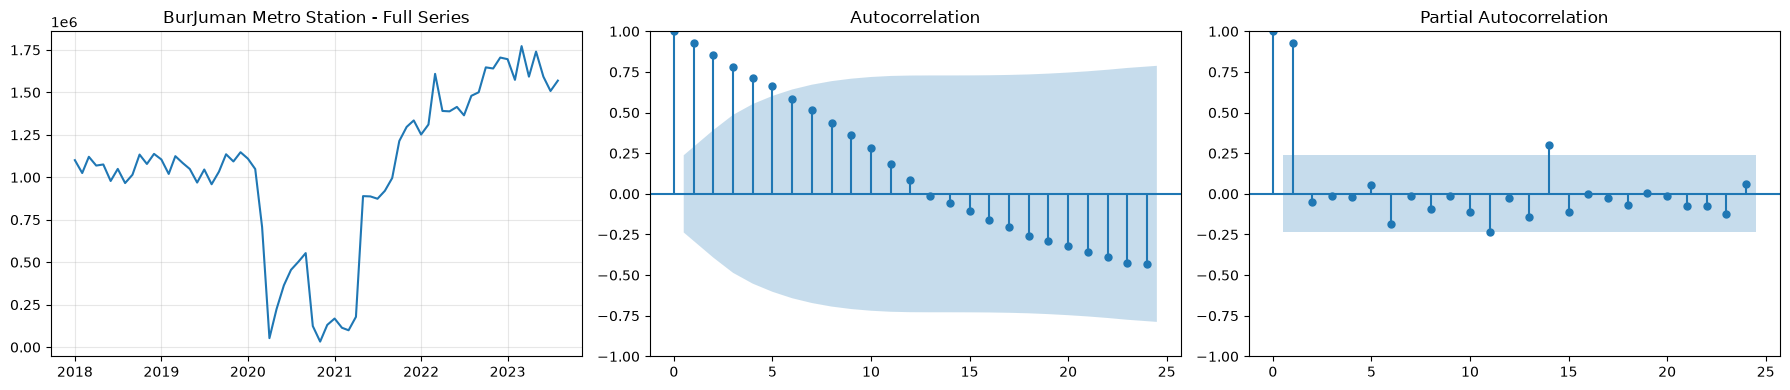

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(s.index, s.values)
axes[0].set_title(f"{station} - Full Series")
axes[0].grid(alpha=0.3)

plot_acf(s.dropna(), lags=24, ax=axes[1])
plot_pacf(s.dropna(), lags=24, ax=axes[2])

plt.tight_layout()
plt.savefig("../docs/sarima_01_acf_pacf_burjuman.png", dpi=150, bbox_inches='tight')
plt.show()

In [10]:
import pmdarima as pm

auto_model = pm.auto_arima(
    s,
    seasonal=True,
    m=12,
    d=None, D=None,
    start_p=0, start_q=0,
    max_p=3, max_q=3,
    max_P=2, max_Q=2,
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True
)
print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=1808.770, Time=0.08 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1804.807, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=1808.770, Time=0.04 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1808.848, Time=0.04 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1802.933, Time=0.00 sec
 ARIMA(0,1,0)(1,0,0)[12] intercept   : AIC=1806.765, Time=0.03 sec
 ARIMA(0,1,0)(0,0,1)[12] intercept   : AIC=1806.764, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=1806.800, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=1806.879, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[12] intercept   : AIC=inf, Time=0.13 sec

Best model:  ARIMA(0,1,0)(0,0,0)[12]          
Total fit time: 0.632 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   68
Model:               SARIMAX(0, 1, 0)   Log Likelihood  

In [11]:
manual_seasonal = pm.ARIMA(order=(1,1,1), seasonal_order=(1,1,1,12))
manual_seasonal.fit(s)
print("Manual seasonal AIC:", manual_seasonal.aic())
print("Auto (no seasonal) AIC:", auto_model.aic())

Manual seasonal AIC: 1509.5976160604619
Auto (no seasonal) AIC: 1802.932762762162


Chosen order: (1, 0, 0) seasonal: (0, 0, 0, 12)
MAE: 151333  RMSE: 166484  MAPE: 9.1%


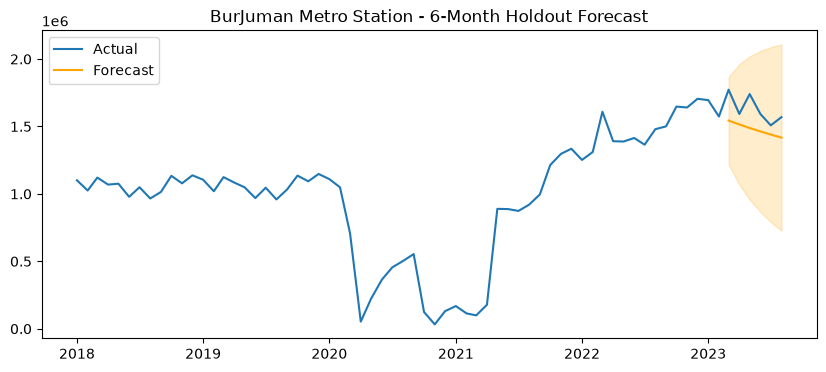

In [12]:
train = s[:-6]
test = s[-6:]

auto_refit = pm.auto_arima(train, seasonal=True, m=12, trace=False, error_action='ignore', 
                             suppress_warnings=True, stepwise=False,  # <- exhaustive search this time, not stepwise
                             max_p=3, max_q=3, max_P=2, max_Q=2)
forecast, conf_int = auto_refit.predict(n_periods=6, return_conf_int=True)

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
mape = (abs((test - forecast) / test)).mean() * 100

print(f"Chosen order: {auto_refit.order} seasonal: {auto_refit.seasonal_order}")
print(f"MAE: {mae:.0f}  RMSE: {rmse:.0f}  MAPE: {mape:.1f}%")

plt.figure(figsize=(10,4))
plt.plot(s.index, s.values, label='Actual')
plt.plot(test.index, forecast, label='Forecast', color='orange')
plt.fill_between(test.index, conf_int[:,0], conf_int[:,1], color='orange', alpha=0.2)
plt.legend()
plt.title(f"{station} - 6-Month Holdout Forecast")
plt.savefig("../docs/sarima_02_burjuman_holdout.png", dpi=150, bbox_inches='tight')
plt.show()

In [13]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

configs = {
    'No seasonal (auto)': ((1,0,0), (0,0,0,12)),
    'Manual seasonal': ((1,1,1), (1,1,1,12)),
    'Simple seasonal': ((1,1,0), (1,1,0,12)),
}

results = {}
for name, (order, seasonal_order) in configs.items():
    try:
        model = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                         enforce_stationarity=False, enforce_invertibility=False)
        fit = model.fit(disp=False)
        fc = fit.get_forecast(steps=6).predicted_mean
        mae = mean_absolute_error(test, fc)
        rmse = np.sqrt(mean_squared_error(test, fc))
        mape = (abs((test - fc) / test)).mean() * 100
        results[name] = {'order': order, 'seasonal': seasonal_order, 'AIC': fit.aic, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape}
    except Exception as e:
        results[name] = {'error': str(e)}

results_df = pd.DataFrame(results).T
print(results_df)

                        order       seasonal          AIC            MAE  \
No seasonal (auto)  (1, 0, 0)  (0, 0, 0, 12)  1645.034335   86790.690783   
Manual seasonal     (1, 1, 1)  (1, 1, 1, 12)   964.364676    191695.1178   
Simple seasonal     (1, 1, 0)  (1, 1, 0, 12)  1000.812357  309488.290653   

                             RMSE       MAPE  
No seasonal (auto)  115004.749294   5.099067  
Manual seasonal     215326.306658  12.096693  
Simple seasonal     363342.725154  19.427884  


In [14]:
def select_best_sarima(series, station_name, holdout=6, min_train_months=24):
    """Try several SARIMA configs, evaluate on holdout, return the best by MAPE."""
    if len(series) < min_train_months + holdout:
        return {'station': station_name, 'status': 'insufficient_data', 'n_months': len(series)}
    
    train = series[:-holdout]
    test = series[-holdout:]
    
    candidate_configs = {
        'nonseasonal_ar1': ((1,0,0), (0,0,0,12)),
        'nonseasonal_arima111': ((1,1,1), (0,0,0,12)),
        'seasonal_111_111': ((1,1,1), (1,1,1,12)),
        'seasonal_110_110': ((1,1,0), (1,1,0,12)),
    }
    
    best = None
    log = []
    for name, (order, seasonal_order) in candidate_configs.items():
        try:
            model = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                             enforce_stationarity=False, enforce_invertibility=False)
            fit = model.fit(disp=False)
            fc = fit.get_forecast(steps=holdout).predicted_mean
            mape = (abs((test - fc) / test)).mean() * 100
            rmse = np.sqrt(mean_squared_error(test, fc))
            mae = mean_absolute_error(test, fc)
            log.append({'config': name, 'order': order, 'seasonal_order': seasonal_order,
                        'MAPE': mape, 'RMSE': rmse, 'MAE': mae, 'AIC': fit.aic})
            if best is None or mape < best['MAPE']:
                best = log[-1]
        except Exception as e:
            log.append({'config': name, 'error': str(e)})
    
    if best is None:
        return {'station': station_name, 'status': 'all_configs_failed'}
    
    # Refit best config on FULL series for final deployment model
    final_model = SARIMAX(series, order=best['order'], seasonal_order=best['seasonal_order'],
                            enforce_stationarity=False, enforce_invertibility=False)
    final_fit = final_model.fit(disp=False)
    
    return {
        'station': station_name,
        'status': 'ok',
        'chosen_config': best['config'],
        'order': best['order'],
        'seasonal_order': best['seasonal_order'],
        'holdout_MAPE': best['MAPE'],
        'holdout_RMSE': best['RMSE'],
        'holdout_MAE': best['MAE'],
        'n_months': len(series),
        'fitted_model': final_fit,
        'all_candidates_log': log
    }

# Test it on BurJuman first
test_result = select_best_sarima(s, station)
print(f"Station: {test_result['station']}")
print(f"Chosen: {test_result['chosen_config']} order={test_result['order']} seasonal={test_result['seasonal_order']}")
print(f"Holdout MAPE: {test_result['holdout_MAPE']:.1f}%")

Station: BurJuman Metro Station
Chosen: nonseasonal_arima111 order=(1, 1, 1) seasonal=(0, 0, 0, 12)
Holdout MAPE: 4.8%


In [15]:
import warnings
warnings.filterwarnings('ignore')  # SARIMAX produces a lot of convergence warnings; we'll rely on MAPE, not warnings, to judge fit quality

all_stations = df['metro_station'].unique()
station_results = {}

for i, st in enumerate(all_stations):
    series = df[df['metro_station'] == st].set_index('date')['trips'].asfreq('MS')
    result = select_best_sarima(series, st)
    station_results[st] = result
    status = result.get('status')
    if status == 'ok':
        print(f"[{i+1}/53] {st}: {result['chosen_config']} MAPE={result['holdout_MAPE']:.1f}%")
    else:
        print(f"[{i+1}/53] {st}: {status}")

[1/53] ADCB Metro Station: nonseasonal_arima111 MAPE=6.5%
[2/53] Abu Baker Al Siddique Metro Station: nonseasonal_arima111 MAPE=7.3%
[3/53] Abu Hail Metro Station: nonseasonal_arima111 MAPE=6.7%
[4/53] Airport Terminal 1 Metro Station: seasonal_110_110 MAPE=6.1%
[5/53] Airport Terminal 3 Metro Station: nonseasonal_arima111 MAPE=6.2%
[6/53] Al Fahidi Metro Station: seasonal_111_111 MAPE=7.2%
[7/53] Al Furjan Metro Station: seasonal_111_111 MAPE=8.4%
[8/53] Al Ghubaiba Metro Station: nonseasonal_arima111 MAPE=6.8%
[9/53] Al Jadaf Metro Station: nonseasonal_arima111 MAPE=9.8%
[10/53] Al Jafiliya Metro Station: nonseasonal_arima111 MAPE=5.2%
[11/53] Al Nahda Metro Station: seasonal_111_111 MAPE=7.3%
[12/53] Al Qiyadah Metro Station: nonseasonal_ar1 MAPE=6.4%
[13/53] Al Qusais Metro Station: nonseasonal_arima111 MAPE=6.2%
[14/53] Al Ras Metro Station: nonseasonal_ar1 MAPE=6.6%
[15/53] Al Rigga Metro Station: nonseasonal_arima111 MAPE=5.8%
[16/53] Baniyas Square Metro Station: nonseasonal_ar

In [16]:
wtc = df[df['metro_station']=='World Trade Centre Metro Station'].sort_values('date')
print(wtc[['date','trips']].tail(15))

           date   trips
3390 2022-06-01  441155
3391 2022-07-01  394419
3392 2022-08-01  452987
3393 2022-09-01  464669
3394 2022-10-01  651448
3395 2022-11-01  639115
3396 2022-12-01  530825
3397 2023-01-01  592884
3398 2023-02-01  668085
3399 2023-03-01  600256
3400 2023-04-01  461120
3401 2023-05-01  595724
3402 2023-06-01  493226
3403 2023-07-01  515097
3404 2023-08-01  472671


In [17]:
summary_rows = []
for st, r in station_results.items():
    if r.get('status') == 'ok':
        summary_rows.append({'station': st, 'config': r['chosen_config'], 'MAPE': r['holdout_MAPE'], 'n_months': r['n_months']})
    else:
        summary_rows.append({'station': st, 'config': r.get('status'), 'MAPE': None, 'n_months': r.get('n_months')})

sarima_summary = pd.DataFrame(summary_rows).sort_values('MAPE', ascending=False)
print(sarima_summary.to_string())
print("\nAverage MAPE:", sarima_summary['MAPE'].mean().round(1))
print("Median MAPE:", sarima_summary['MAPE'].median().round(1))
print("\nConfig distribution:")
print(sarima_summary['config'].value_counts())

sarima_summary.to_csv("../docs/sarima_results_summary.csv", index=False)

                                  station                config       MAPE  n_months
29                     EXPO Metro Station      seasonal_111_111  29.681292        42
52       World Trade Centre Metro Station      seasonal_111_111  28.090822        68
27      Dubai Internet City Metro Station  nonseasonal_arima111  15.737459        68
32                   Energy Metro Station  nonseasonal_arima111  14.398483        68
43                  Nakheel Metro Station       nonseasonal_ar1  13.719709        68
20         DAMAC Properties Metro Station       nonseasonal_ar1  12.924783        68
28    Dubai Investment Park Metro Station      seasonal_111_111  12.387897        42
40    Jumeirah Golf Estates Metro Station  nonseasonal_arima111  11.051881        42
22                   Danube Metro Station  nonseasonal_arima111  10.834439        68
21                     DMCC Metro Station       nonseasonal_ar1  10.002573        68
8                  Al Jadaf Metro Station  nonseasonal_arima111  

In [18]:
wtc_series = df[df['metro_station']=='World Trade Centre Metro Station'].set_index('date')['trips'].asfreq('MS')
wtc_check = select_best_sarima(wtc_series, 'World Trade Centre Metro Station')

for entry in wtc_check['all_candidates_log']:
    print(entry)

{'config': 'nonseasonal_ar1', 'order': (1, 0, 0), 'seasonal_order': (0, 0, 0, 12), 'MAPE': np.float64(28.91239704314054), 'RMSE': np.float64(154207.48139453336), 'MAE': 143931.37485125815, 'AIC': np.float64(1544.6504419638345)}
{'config': 'nonseasonal_arima111', 'order': (1, 1, 1), 'seasonal_order': (0, 0, 0, 12), 'MAPE': np.float64(30.01939139448031), 'RMSE': np.float64(159484.74550168653), 'MAE': 149693.86252452023, 'AIC': np.float64(1493.886595615561)}
{'config': 'seasonal_111_111', 'order': (1, 1, 1), 'seasonal_order': (1, 1, 1, 12), 'MAPE': np.float64(28.0908222464037), 'RMSE': np.float64(164617.66886007608), 'MAE': 145799.04356696195, 'AIC': np.float64(908.3341777879291)}
{'config': 'seasonal_110_110', 'order': (1, 1, 0), 'seasonal_order': (1, 1, 0, 12), 'MAPE': np.float64(36.15909216414382), 'RMSE': np.float64(194956.61314760018), 'MAE': 182270.08181139463, 'AIC': np.float64(932.0938337509211)}


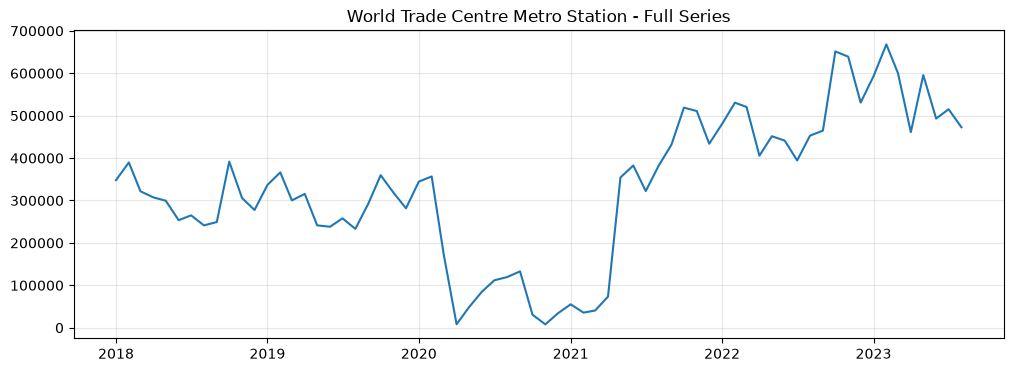

In [19]:
plt.figure(figsize=(12,4))
plt.plot(wtc_series.index, wtc_series.values)
plt.title("World Trade Centre Metro Station - Full Series")
plt.grid(alpha=0.3)
plt.savefig("../docs/sarima_03_wtc_investigation.png", dpi=150, bbox_inches='tight')
plt.show()

In [20]:
import os
import pickle

os.makedirs("../models/sarima", exist_ok=True)

for st, r in station_results.items():
    if r.get('status') == 'ok':
        safe_name = st.replace('/', '_').replace(' ', '_')
        with open(f"../models/sarima/{safe_name}.pkl", "wb") as f:
            pickle.dump(r['fitted_model'], f)

print("Saved", sum(1 for r in station_results.values() if r.get('status')=='ok'), "fitted SARIMA models.")

Saved 53 fitted SARIMA models.


In [21]:
import time

def select_best_sarima_gridsearch(series, station_name, holdout=6, min_train_months=24):
    """Use auto_arima exhaustive grid search on train, validate on holdout, refit best on full data."""
    if len(series) < min_train_months + holdout:
        return {'station': station_name, 'status': 'insufficient_data', 'n_months': len(series)}
    
    train = series[:-holdout]
    test = series[-holdout:]
    
    try:
        search = pm.auto_arima(
            train,
            seasonal=True, m=12,
            start_p=0, start_q=0, max_p=3, max_q=3,
            start_P=0, start_Q=0, max_P=2, max_Q=2,
            d=None, D=None,
            stepwise=False,          # exhaustive grid search
            error_action='ignore',
            suppress_warnings=True,
            n_jobs=-1                # use all CPU cores to speed this up
        )
        order = search.order
        seasonal_order = search.seasonal_order
    except Exception as e:
        return {'station': station_name, 'status': 'search_failed', 'error': str(e)}
    
    try:
        model = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                         enforce_stationarity=False, enforce_invertibility=False)
        fit = model.fit(disp=False)
        fc = fit.get_forecast(steps=holdout).predicted_mean
        mape = (abs((test - fc) / test)).mean() * 100
        rmse = np.sqrt(mean_squared_error(test, fc))
        mae = mean_absolute_error(test, fc)
    except Exception as e:
        return {'station': station_name, 'status': 'fit_failed', 'error': str(e)}
    
    # Refit on FULL series for deployment
    final_model = SARIMAX(series, order=order, seasonal_order=seasonal_order,
                            enforce_stationarity=False, enforce_invertibility=False)
    final_fit = final_model.fit(disp=False)
    
    return {
        'station': station_name, 'status': 'ok',
        'order': order, 'seasonal_order': seasonal_order,
        'holdout_MAPE': mape, 'holdout_RMSE': rmse, 'holdout_MAE': mae,
        'train_AIC': search.aic(), 'n_months': len(series),
        'fitted_model': final_fit
    }

# Test on BurJuman first to confirm it works and check timing
t0 = time.time()
test_result = select_best_sarima_gridsearch(s, station)
print(f"Took {time.time()-t0:.1f} sec")
print(f"Order: {test_result['order']} Seasonal: {test_result['seasonal_order']}")
print(f"Holdout MAPE: {test_result['holdout_MAPE']:.1f}%")

Took 17.6 sec
Order: (1, 0, 0) Seasonal: (0, 0, 0, 12)
Holdout MAPE: 5.1%


In [22]:
search = pm.auto_arima(
    s[:-6], seasonal=True, m=12,
    start_p=0, start_q=0, max_p=3, max_q=3,
    start_P=0, start_Q=0, max_P=2, max_Q=2,
    d=None, D=None, stepwise=False,
    error_action='ignore', suppress_warnings=True,
    n_jobs=-1, trace=False, return_valid_fits=True
)
print(type(search))
print(len(search))
print(search[0])
print(type(search[0]))

<class 'tuple'>
85
 ARIMA(1,0,0)(0,0,0)[12] intercept
<class 'pmdarima.arima.arima.ARIMA'>


In [23]:
def select_best_sarima_gridsearch_v2(series, station_name, holdout=6, min_train_months=24, n_candidates=5):
    if len(series) < min_train_months + holdout:
        return {'station': station_name, 'status': 'insufficient_data', 'n_months': len(series)}
    
    train = series[:-holdout]
    test = series[-holdout:]
    
    try:
        search = pm.auto_arima(
            train, seasonal=True, m=12,
            start_p=0, start_q=0, max_p=3, max_q=3,
            start_P=0, start_Q=0, max_P=2, max_Q=2,
            d=None, D=None, stepwise=False,
            error_action='ignore', suppress_warnings=True,
            n_jobs=-1, trace=False, return_valid_fits=True
        )
        # search is a tuple of ARIMA objects, sorted best-AIC-first; take the top N
        candidates = search[:n_candidates]
    except Exception as e:
        return {'station': station_name, 'status': 'search_failed', 'error': str(e)}
    
    best = None
    for cand in candidates:
        order, seasonal_order = cand.order, cand.seasonal_order  # these ARE attributes on ARIMA objects, this part was fine
        try:
            model = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                             enforce_stationarity=False, enforce_invertibility=False)
            fit = model.fit(disp=False)
            fc = fit.get_forecast(steps=holdout).predicted_mean
            mape = (abs((test - fc) / test)).mean() * 100
            rmse = np.sqrt(mean_squared_error(test, fc))
            mae = mean_absolute_error(test, fc)
            if best is None or mape < best['MAPE']:
                best = {'order': order, 'seasonal_order': seasonal_order, 'MAPE': mape, 'RMSE': rmse, 'MAE': mae}
        except Exception:
            continue
    
    if best is None:
        return {'station': station_name, 'status': 'all_candidates_failed'}
    
    final_model = SARIMAX(series, order=best['order'], seasonal_order=best['seasonal_order'],
                            enforce_stationarity=False, enforce_invertibility=False)
    final_fit = final_model.fit(disp=False)
    
    return {
        'station': station_name, 'status': 'ok',
        'order': best['order'], 'seasonal_order': best['seasonal_order'],
        'holdout_MAPE': best['MAPE'], 'holdout_RMSE': best['RMSE'], 'holdout_MAE': best['MAE'],
        'n_months': len(series), 'fitted_model': final_fit
    }

t0 = time.time()
test_result = select_best_sarima_gridsearch_v2(s, station)
print(f"Took {time.time()-t0:.1f} sec")
print(f"Order: {test_result['order']} Seasonal: {test_result['seasonal_order']}")
print(f"Holdout MAPE: {test_result['holdout_MAPE']:.1f}%")

Took 7.1 sec
Order: (1, 0, 0) Seasonal: (0, 0, 0, 12)
Holdout MAPE: 5.1%


In [24]:
station_results_v2 = {}
t0 = time.time()

for i, st in enumerate(all_stations):
    series = df[df['metro_station'] == st].set_index('date')['trips'].asfreq('MS')
    result = select_best_sarima_gridsearch_v2(series, st)
    station_results_v2[st] = result
    status = result.get('status')
    elapsed = time.time() - t0
    if status == 'ok':
        print(f"[{i+1}/53] ({elapsed:.0f}s elapsed) {st}: order={result['order']} seasonal={result['seasonal_order']} MAPE={result['holdout_MAPE']:.1f}%")
    else:
        print(f"[{i+1}/53] ({elapsed:.0f}s elapsed) {st}: {status}")

print(f"\nTotal time: {time.time()-t0:.0f} seconds")

[1/53] (7s elapsed) ADCB Metro Station: order=(1, 0, 0) seasonal=(1, 0, 0, 12) MAPE=7.6%
[2/53] (14s elapsed) Abu Baker Al Siddique Metro Station: order=(2, 0, 0) seasonal=(0, 0, 0, 12) MAPE=9.4%
[3/53] (22s elapsed) Abu Hail Metro Station: order=(1, 0, 0) seasonal=(0, 0, 0, 12) MAPE=9.2%
[4/53] (29s elapsed) Airport Terminal 1 Metro Station: order=(1, 0, 1) seasonal=(0, 0, 0, 12) MAPE=9.8%
[5/53] (33s elapsed) Airport Terminal 3 Metro Station: order=(3, 0, 0) seasonal=(0, 0, 0, 12) MAPE=8.1%
[6/53] (36s elapsed) Al Fahidi Metro Station: order=(1, 0, 0) seasonal=(1, 0, 0, 12) MAPE=9.4%
[7/53] (36s elapsed) Al Furjan Metro Station: search_failed
[8/53] (39s elapsed) Al Ghubaiba Metro Station: order=(1, 0, 0) seasonal=(1, 0, 0, 12) MAPE=8.5%
[9/53] (44s elapsed) Al Jadaf Metro Station: order=(0, 1, 1) seasonal=(0, 0, 0, 12) MAPE=9.6%
[10/53] (48s elapsed) Al Jafiliya Metro Station: order=(1, 0, 0) seasonal=(0, 0, 0, 12) MAPE=5.2%
[11/53] (51s elapsed) Al Nahda Metro Station: order=(1, 0,

In [25]:
summary_v2 = []
for st, r in station_results_v2.items():
    if r.get('status') == 'ok':
        summary_v2.append({'station': st, 'order': r['order'], 'seasonal_order': r['seasonal_order'], 'MAPE_v2': r['holdout_MAPE']})
    else:
        summary_v2.append({'station': st, 'order': None, 'seasonal_order': None, 'MAPE_v2': None, 'status': r.get('status')})

v2_df = pd.DataFrame(summary_v2)

# Compare against original 4-candidate results
v1_df = sarima_summary[['station','MAPE']].rename(columns={'MAPE':'MAPE_v1'})
comparison = v1_df.merge(v2_df, on='station', how='outer')
comparison['improved'] = comparison['MAPE_v2'] < comparison['MAPE_v1']
comparison['diff'] = comparison['MAPE_v1'] - comparison['MAPE_v2']

print(comparison.sort_values('diff', ascending=False).to_string())
print(f"\nStations improved: {comparison['improved'].sum()} / {comparison['MAPE_v2'].notna().sum()}")
print(f"v1 avg MAPE: {comparison['MAPE_v1'].mean():.2f}  v2 avg MAPE: {comparison['MAPE_v2'].mean():.2f}")
print(f"v1 median MAPE: {comparison['MAPE_v1'].median():.2f}  v2 median MAPE: {comparison['MAPE_v2'].median():.2f}")

# Investigate the two failures
for st in ['Al Furjan Metro Station', 'Discovery Gardens Metro Station']:
    print(f"\n{st}: {station_results_v2[st]}")

                                  station    MAPE_v1      order seasonal_order    MAPE_v2         status  improved       diff
52       World Trade Centre Metro Station  28.090822  (2, 1, 0)  (0, 0, 1, 12)  10.691961            NaN      True  17.398861
20         DAMAC Properties Metro Station  12.924783  (1, 0, 1)  (1, 0, 0, 12)   8.029141            NaN      True   4.895642
21                     DMCC Metro Station  10.002573  (1, 0, 0)  (0, 0, 1, 12)   8.489309            NaN      True   1.513264
13                   Al Ras Metro Station   6.628916  (1, 0, 1)  (0, 0, 0, 12)   5.933772            NaN      True   0.695144
43                  Nakheel Metro Station  13.719709  (1, 0, 0)  (0, 0, 1, 12)  13.168406            NaN      True   0.551303
15           Baniyas Square Metro Station   5.604993  (0, 1, 0)  (1, 0, 0, 12)   5.192309            NaN      True   0.412684
51                    Union Metro Station   5.736008  (1, 0, 0)  (1, 0, 0, 12)   5.358148            NaN      True   0

In [26]:
def select_best_sarima_final(series, station_name, holdout=6, min_train_months=24):
    if len(series) < min_train_months + holdout:
        return {'station': station_name, 'status': 'insufficient_data', 'n_months': len(series)}
    
    # Interpolate any internal NaN gaps (document this as a limitation for affected stations)
    had_nans = series.isna().sum()
    series_clean = series.interpolate(method='linear').bfill().ffill()
    
    train = series_clean[:-holdout]
    test = series_clean[-holdout:]
    
    # Hand-picked structurally diverse candidates (from v1)
    fixed_candidates = [((1,0,0),(0,0,0,12)), ((1,1,1),(0,0,0,12)), ((1,1,1),(1,1,1,12)), ((1,1,0),(1,1,0,12))]
    
    # AIC-ranked candidates from auto_arima
    try:
        search = pm.auto_arima(train, seasonal=True, m=12, start_p=0, start_q=0, max_p=3, max_q=3,
                                start_P=0, start_Q=0, max_P=2, max_Q=2, d=None, D=None, stepwise=False,
                                error_action='ignore', suppress_warnings=True, n_jobs=-1, return_valid_fits=True)
        auto_candidates = [(c.order, c.seasonal_order) for c in search[:5]]
    except Exception:
        auto_candidates = []
    
    all_candidates = list(set(fixed_candidates + auto_candidates))
    
    best = None
    for order, seasonal_order in all_candidates:
        try:
            model = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                             enforce_stationarity=False, enforce_invertibility=False)
            fit = model.fit(disp=False)
            fc = fit.get_forecast(steps=holdout).predicted_mean
            mape = (abs((test - fc) / test)).mean() * 100
            rmse = np.sqrt(mean_squared_error(test, fc))
            mae = mean_absolute_error(test, fc)
            if best is None or mape < best['MAPE']:
                best = {'order': order, 'seasonal_order': seasonal_order, 'MAPE': mape, 'RMSE': rmse, 'MAE': mae}
        except Exception:
            continue
    
    if best is None:
        return {'station': station_name, 'status': 'all_candidates_failed'}
    
    final_model = SARIMAX(series_clean, order=best['order'], seasonal_order=best['seasonal_order'],
                            enforce_stationarity=False, enforce_invertibility=False)
    final_fit = final_model.fit(disp=False)
    
    return {
        'station': station_name, 'status': 'ok', 'order': best['order'], 'seasonal_order': best['seasonal_order'],
        'holdout_MAPE': best['MAPE'], 'holdout_RMSE': best['RMSE'], 'holdout_MAE': best['MAE'],
        'n_candidates_tried': len(all_candidates), 'interpolated_months': int(had_nans),
        'n_months': len(series), 'fitted_model': final_fit
    }

t0 = time.time()
station_results_final = {}
for i, st in enumerate(all_stations):
    series = df[df['metro_station'] == st].set_index('date')['trips'].asfreq('MS')
    result = select_best_sarima_final(series, st)
    station_results_final[st] = result
    status = result.get('status')
    if status == 'ok':
        note = f" (interpolated {result['interpolated_months']} months)" if result['interpolated_months'] > 0 else ""
        print(f"[{i+1}/53] {st}: {result['order']} {result['seasonal_order']} MAPE={result['holdout_MAPE']:.1f}%{note}")
    else:
        print(f"[{i+1}/53] {st}: {status}")

print(f"\nTotal time: {time.time()-t0:.0f}s")

[1/53] ADCB Metro Station: (1, 1, 1) (0, 0, 0, 12) MAPE=6.5%
[2/53] Abu Baker Al Siddique Metro Station: (1, 1, 1) (0, 0, 0, 12) MAPE=7.3%
[3/53] Abu Hail Metro Station: (1, 1, 1) (0, 0, 0, 12) MAPE=6.7%
[4/53] Airport Terminal 1 Metro Station: (1, 1, 0) (1, 1, 0, 12) MAPE=6.1%
[5/53] Airport Terminal 3 Metro Station: (1, 1, 1) (0, 0, 0, 12) MAPE=6.2%
[6/53] Al Fahidi Metro Station: (1, 1, 1) (1, 1, 1, 12) MAPE=7.2%
[7/53] Al Furjan Metro Station: (0, 1, 0) (0, 0, 1, 12) MAPE=8.1% (interpolated 2 months)
[8/53] Al Ghubaiba Metro Station: (1, 1, 1) (0, 0, 0, 12) MAPE=6.8%
[9/53] Al Jadaf Metro Station: (0, 1, 1) (0, 0, 0, 12) MAPE=9.6%
[10/53] Al Jafiliya Metro Station: (1, 1, 1) (0, 0, 0, 12) MAPE=5.2%
[11/53] Al Nahda Metro Station: (1, 1, 1) (1, 1, 1, 12) MAPE=7.3%
[12/53] Al Qiyadah Metro Station: (0, 1, 0) (1, 0, 0, 12) MAPE=6.2%
[13/53] Al Qusais Metro Station: (1, 1, 1) (0, 0, 0, 12) MAPE=6.2%
[14/53] Al Ras Metro Station: (1, 0, 1) (0, 0, 0, 12) MAPE=5.9%
[15/53] Al Rigga Metro 

In [27]:
final_summary = []
for st, r in station_results_final.items():
    if r.get('status') == 'ok':
        final_summary.append({'station': st, 'order': r['order'], 'seasonal_order': r['seasonal_order'],
                               'MAPE_final': r['holdout_MAPE'], 'interpolated_months': r['interpolated_months']})

final_df = pd.DataFrame(final_summary)

print("Average MAPE:", final_df['MAPE_final'].mean().round(2))
print("Median MAPE:", final_df['MAPE_final'].median().round(2))
print("\nStations needing interpolation:", (final_df['interpolated_months'] > 0).sum())

# Full three-way comparison
three_way = comparison[['station','MAPE_v1','MAPE_v2']].merge(
    final_df[['station','MAPE_final']], on='station', how='outer'
)
print("\n", three_way.describe()[['MAPE_v1','MAPE_v2','MAPE_final']])

final_df.to_csv("../docs/sarima_results_final.csv", index=False)

Average MAPE: 8.2
Median MAPE: 7.27

Stations needing interpolation: 7

          MAPE_v1    MAPE_v2  MAPE_final
count  53.000000  46.000000   53.000000
mean    8.753572   8.676797    8.201373
std     4.689660   2.637734    3.805199
min     4.494345   4.618136    4.494345
25%     6.613457   7.141142    6.527895
50%     7.308381   8.134171    7.274074
75%     8.641348   9.621990    8.489309
max    29.681292  15.555929   29.652365


In [28]:
for st, r in station_results_final.items():
    if r.get('status') == 'ok':
        safe_name = st.replace('/', '_').replace(' ', '_')
        with open(f"../models/sarima/{safe_name}.pkl", "wb") as f:
            pickle.dump(r['fitted_model'], f)

print("Saved", sum(1 for r in station_results_final.values() if r.get('status')=='ok'), "final fitted SARIMA models.")

Saved 53 final fitted SARIMA models.


In [29]:
final_summary_full = []
for st, r in station_results_final.items():
    if r.get('status') == 'ok':
        final_summary_full.append({
            'station': st, 'order': r['order'], 'seasonal_order': r['seasonal_order'],
            'MAPE_sarima': r['holdout_MAPE'], 'RMSE_sarima': r['holdout_RMSE'], 'MAE_sarima': r['holdout_MAE'],
            'interpolated_months': r['interpolated_months']
        })

sarima_full_df = pd.DataFrame(final_summary_full)
sarima_full_df.to_csv("../docs/sarima_results_final.csv", index=False)
print("Re-saved with RMSE/MAE:", sarima_full_df.shape)
print(sarima_full_df.head())

Re-saved with RMSE/MAE: (53, 7)
                               station      order seasonal_order  MAPE_sarima  \
0                   ADCB Metro Station  (1, 1, 1)  (0, 0, 0, 12)     6.545403   
1  Abu Baker Al Siddique Metro Station  (1, 1, 1)  (0, 0, 0, 12)     7.274074   
2               Abu Hail Metro Station  (1, 1, 1)  (0, 0, 0, 12)     6.743128   
3     Airport Terminal 1 Metro Station  (1, 1, 0)  (1, 1, 0, 12)     6.057199   
4     Airport Terminal 3 Metro Station  (1, 1, 1)  (0, 0, 0, 12)     6.213670   

    RMSE_sarima    MAE_sarima  interpolated_months  
0  70589.459052  58278.974237                    0  
1  48753.027693  39115.489423                    0  
2  33050.999730  25095.240200                    0  
3  22841.468316  19816.753101                    0  
4  14721.012200  12059.004109                    0  
